# Explore the data!

This here notebook is just to play around with the data, load it, look at it, start plotting some graphs for curiosity's sake.

In [40]:
# imports
import numpy as np
import matplotlib as mpl
import pandas as pd
import pickle
from pathlib import Path


In [41]:
# Select data path and session
data_dir = Path("C:/Users/cleme/Documents/etheremin/data")
prefix = "FETA_hs_0_playback_0.005"


# Load the pickle files
with (data_dir / f"{prefix}_data_ss").open("rb") as f:
    neural_data = pickle.load(f)

with (data_dir / f"{prefix}_feature_ss").open("rb") as f:
    features = pickle.load(f)

with (data_dir / f"{prefix}_neuron_idx_ss").open("rb") as f:
    neuron_ids = pickle.load(f)

## Getting a hold of the data
See below: each animal has 3 files that describe the neural data, features, and neuron indexes. Each file is a list of 12 sessions (there's more originally, but i think the preprocessing step selects 12 for each in some way). So to look at one experiment, you need to look at the same element of each pkl file.

In [42]:
# Types and shapes
for name, obj in [
    ("neural_data", neural_data),
    ("features", features),
    ("neuron_ids", neuron_ids),
]:
    session = obj[0]
    print(f"{name}: {type(obj).__name__}, {len(obj)} sessions")
    print(f"  First session: {type(session).__name__}")
    print(f"  Shape: {session.shape}" if hasattr(session, "shape")
          else f"  Length: {len(session)}")

neural_data: list, 12 sessions
  First session: ndarray
  Shape: (14, 482730)
features: list, 12 sessions
  First session: DataFrame
  Shape: (482730, 17)
neuron_ids: list, 12 sessions
  First session: list
  Length: 14


In [43]:
# Choose a session and ranges (stop values excluded)
session = 0
unit_start, unit_stop = 0, 5
bin_start, bin_stop = 1000, 1010

print(f"Session {session} — neural data: units × time bins")
display(neural_data[session][unit_start:unit_stop, bin_start:bin_stop])

print("Features — same time bins:")
display(features[session].iloc[bin_start:bin_stop])

print("Neuron IDs — same units:")
display(neuron_ids[session][unit_start:unit_stop])

Session 0 — neural data: units × time bins


array([[0., 1., 0., 0., 0., 1., 1., 0., 1., 0.],
       [0., 0., 0., 0., 0., 0., 0., 1., 0., 0.],
       [0., 0., 0., 0., 0., 0., 0., 1., 0., 0.],
       [0., 1., 0., 1., 0., 0., 1., 0., 0., 0.],
       [0., 0., 1., 1., 1., 2., 0., 1., 0., 0.]])

Features — same time bins:


,Played_frequency,Condition,Block,Frequency_changes,Mock_frequency,Mock_change,Change_direction,Mock_direction,Speed_x,Speed_x_signed,Sound_speed,Position,Freq_position,Speed_bin,Acc_x_signed,Acc_x,Acc_sound
1000,2000.0,0.0,0.0,False,0.0,False,0,0,1.434196,1.434196,1.434196,16.815563,16.815563,3.0,0.311084,0.311084,0.311084
1001,1727.0,0.0,0.0,True,0.0,False,-1,0,1.715702,1.715702,1.715702,16.832720,16.832720,3.0,0.281506,0.281506,0.281506
1002,1727.0,0.0,0.0,False,0.0,False,0,0,1.972155,1.972155,1.972155,16.852441,16.852441,3.0,0.256453,0.256453,0.256453
1003,2000.0,0.0,0.0,True,0.0,False,1,0,2.208858,2.208858,2.208858,16.874530,16.874530,4.0,0.236703,0.236703,0.236703
1004,2000.0,0.0,0.0,False,0.0,False,0,0,2.431354,2.431354,2.431354,16.898844,16.898844,4.0,0.222496,0.222496,0.222496
1005,1727.0,0.0,0.0,True,0.0,False,-1,0,2.644886,2.644886,2.644886,16.925292,16.925292,4.0,0.213532,0.213532,0.213532
1006,2000.0,0.0,0.0,True,0.0,False,1,0,2.853903,2.853903,2.853903,16.953831,16.953831,4.0,0.209016,0.209016,0.209016
1007,2000.0,0.0,0.0,False,0.0,False,0,0,3.061634,3.061634,3.061634,16.984448,16.984448,5.0,0.207731,0.207731,0.207731
1008,1727.0,0.0,0.0,True,0.0,False,-1,0,3.269789,3.269789,3.269789,17.017146,17.017146,5.0,0.208155,0.208155,0.208155
1009,1727.0,0.0,0.0,False,0.0,False,0,0,3.478383,3.478383,3.478383,17.051930,17.051930,5.0,0.208594,0.208594,0.208594


Neuron IDs — same units:


['FETA_20251204_SESSION_00_headstage_0_neuron0',
 'FETA_20251204_SESSION_00_headstage_0_neuron1',
 'FETA_20251204_SESSION_00_headstage_0_neuron2',
 'FETA_20251204_SESSION_00_headstage_0_neuron3',
 'FETA_20251204_SESSION_00_headstage_0_neuron4']

## Plotting features

Now lets look at the features to understand the important ones, what they look like etc.

In [44]:
# imports
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.ndimage import gaussian_filter1d

# seaborn settings
sns.set_theme(
    style="ticks",
    context="notebook",
    palette="colorblind",
    rc={
        "figure.figsize": (10, 4),
        "figure.dpi": 120,
        "axes.spines.top": False,
        "axes.spines.right": False,
    },
)

# Select session and define dt
session = 0
dt = 0.005

### Plotting a unit's FR with gaussian smoothing

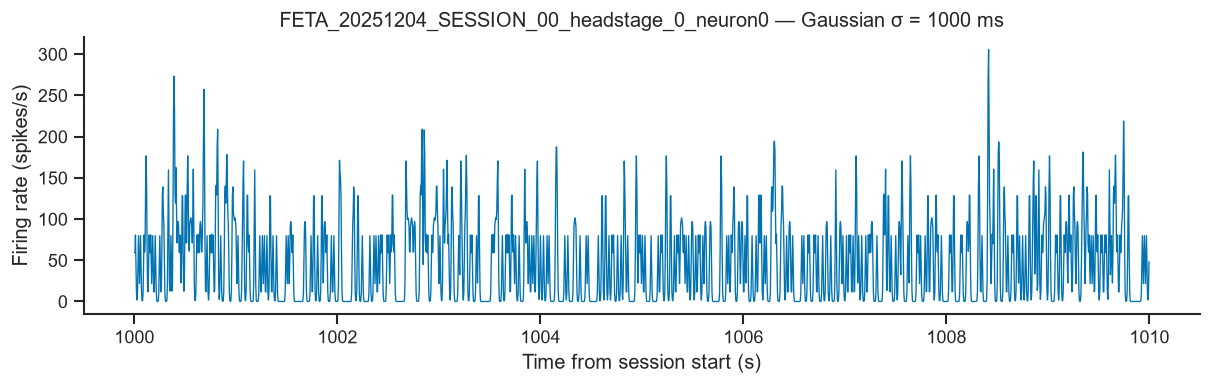

In [45]:
# Choose neuron, time window, and smoothing
unit = 0
start_s = 1000
stop_s = 1010
dt = 0.005
# sigma is gaussian smoothing value, expressed in bins
sigma = 1

counts = neural_data[session][unit]

start_bin = int(start_s / dt)
stop_bin = len(counts) if stop_s is None else min(int(stop_s / dt), len(counts))

# Convert counts to spikes/s and smooth the full recording
smooth_rate = gaussian_filter1d(
    counts.astype(float) / dt,
    sigma
)

activity = smooth_rate[start_bin:stop_bin]
time_s = (start_bin + np.arange(len(activity))) * dt

fig, ax = plt.subplots(figsize=(12, 3))
ax.plot(time_s, activity, linewidth=0.8)
ax.set(
    xlabel="Time from session start (s)",
    ylabel="Firing rate (spikes/s)",
    title=f"{neuron_ids[session][unit]} — Gaussian σ = {sigma * 1000:g} ms",
)
plt.show()

### Plotting the session's different features

Here, we will look specifically at the following:
Played_frequency
Condition
Frequency_changes
Mock_frequency
Mock_change

There's others, but i need to check if they are real or reliquates

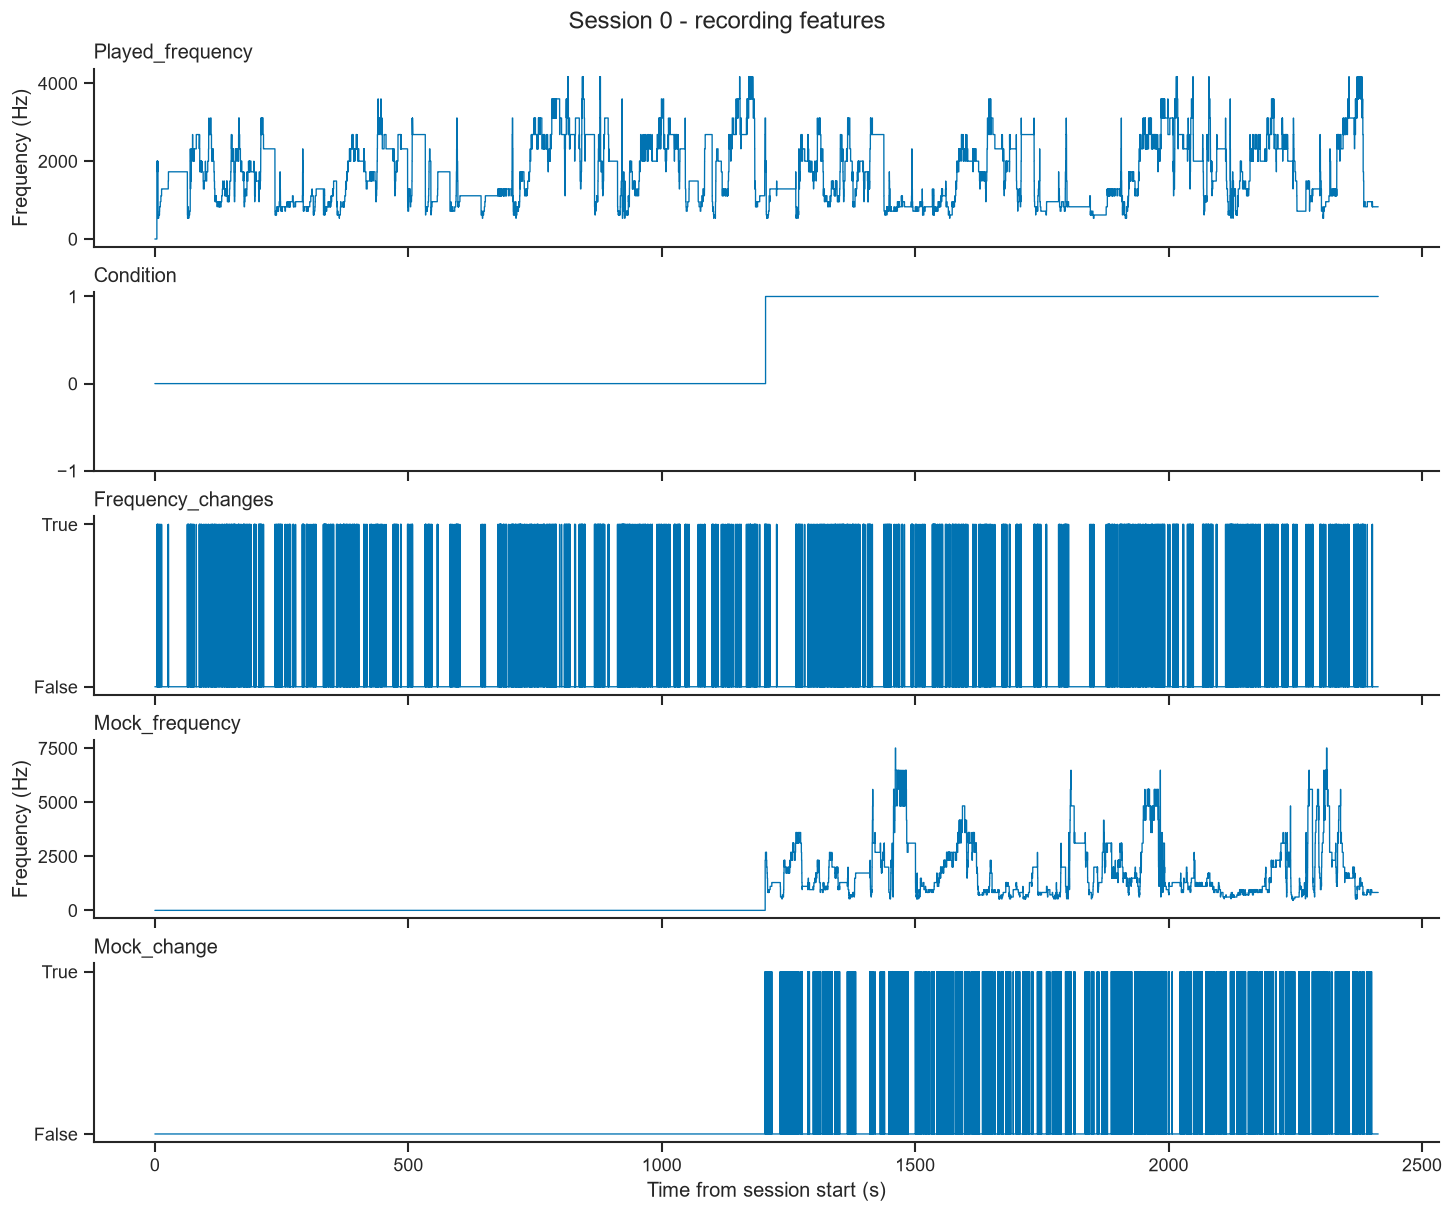

In [46]:
import numpy as np
import matplotlib.pyplot as plt


start_s = 0
stop_s = None  # use None for the full session

features_to_plot = [
    "Played_frequency",
    "Condition",
    "Frequency_changes",
    "Mock_frequency",
    "Mock_change",
]

# Convert the selected time window to bin indices
start_bin = int(start_s / dt)
stop_bin = (
    len(features[session])
    if stop_s is None
    else min(int(stop_s / dt), len(features[session]))
)
time_s = np.arange(start_bin, stop_bin) * dt

# One panel per feature, all sharing the same time axis
fig, axes = plt.subplots(
    len(features_to_plot), 1,
    figsize=(12, 10), sharex=True, layout="constrained",
)

for ax, feature in zip(axes, features_to_plot):
    ax.step(
        time_s,
        features[session][feature].iloc[start_bin:stop_bin],
        where="post",
        linewidth=0.8,
    )
    ax.set_title(feature, loc="left")
    if feature in ("Played_frequency", "Mock_frequency"):
        ax.set_ylabel("Frequency (Hz)")
    elif feature in ("Frequency_changes", "Mock_change"):
        ax.set_yticks([0, 1], labels=["False", "True"])
    elif feature == "Condition":
        ax.set_yticks([-1, 0, 1])

axes[-1].set_xlabel("Time from session start (s)")
fig.suptitle(f"Session {session} - recording features")
plt.show()


## Single-neuron responses aligned to frequency changes

Each row of `event_responses` contains one selected neuron's Gaussian-smoothed spike counts around one frequency-change event. `raw_event_responses` retains the unsmoothed counts for comparison. Columns are 5 ms bins relative to the event: **-0.300 s up to, but excluding, +0.050 s** (70 bins). The event bin is at time zero.

We use every bin marked `Frequency_changes == True`, across all conditions. Consecutive True bins are separate events. Windows can overlap; events near either session boundary are excluded if their full window is unavailable. The full-session trace is smoothed before extracting windows, without baseline subtraction. `sigma_bins` is the Gaussian standard deviation in bins (default: 1 bin = 5 ms). The mean plot converts smoothed counts per bin to spikes/s. Gaussian smoothing is symmetric: activity after an event can spread into the pre-event period, so it should not be used to infer precise response onset times.

Responses are split by `Condition` **at the event bin**: tracking (`0`) and playback (`1`). Other conditions (including `-1`) remain in the full matrix but are excluded from this comparison. A window may cross a condition boundary; it keeps the label at time zero.


In [47]:
# Select one neuron and the event window
import numpy as np
from scipy.ndimage import gaussian_filter1d

session = 11
unit = 0
dt = 0.005
before_s = 1
after_s = 0.3
sigma_bins = 3  # Gaussian standard deviation: 1 bin = 5 ms

before_bins = int(round(before_s / dt))
after_bins = int(round(after_s / dt))
relative_bins = np.arange(-before_bins, after_bins)
event_time_s = relative_bins * dt

neuron_counts = np.asarray(neural_data[session][unit])
if len(neuron_counts) != len(features[session]):
    raise ValueError("Neural data and features must have the same number of time bins.")

if not np.isfinite(sigma_bins) or sigma_bins <= 0:
    raise ValueError("sigma_bins must be positive and finite.")

# Smooth along time before extracting windows; keep neuron_counts unchanged.
smoothed_counts = gaussian_filter1d(
    neuron_counts.astype(float), sigma=sigma_bins, mode="reflect",
)
print(f"Gaussian sigma: {sigma_bins:g} bins = {sigma_bins * dt * 1000:g} ms")


Gaussian sigma: 3 bins = 15 ms


In [48]:
# Find events and retain only those with a complete window
all_event_bins = np.flatnonzero(
    features[session]["Frequency_changes"].fillna(False).eq(True).to_numpy()
)
complete_window = (
    (all_event_bins >= before_bins)
    & (all_event_bins + after_bins <= len(neuron_counts))
)
event_bins = all_event_bins[complete_window]

# Rows = events; columns = time bins relative to each event
# Empty selections retain the shape (0, number of time bins).
raw_event_responses = neuron_counts[event_bins[:, None] + relative_bins[None, :]]
event_responses = smoothed_counts[event_bins[:, None] + relative_bins[None, :]]

print("Neuron:", neuron_ids[session][unit])
print("Frequency-change events:", len(all_event_bins))
print("Skipped at session boundaries:", np.count_nonzero(~complete_window))
print("Response matrix (events, time bins):", event_responses.shape)
print("Event bin column:", before_bins)

# The row order matches event_bins; these are times from session start.
event_times_s = event_bins * dt


Neuron: FETA_20251216_SESSION_00_headstage_0_neuron0
Frequency-change events: 4487
Skipped at session boundaries: 0
Response matrix (events, time bins): (4487, 260)
Event bin column: 200


In [49]:
# Split rows using the condition at each retained frequency-change event
# iloc selects by bin position, in exactly the same order as event_responses.
event_conditions = features[session]["Condition"].iloc[event_bins]
tracking_mask = event_conditions.eq(0).fillna(False).to_numpy(dtype=bool)
playback_mask = event_conditions.eq(1).fillna(False).to_numpy(dtype=bool)

tracking_responses = event_responses[tracking_mask]
playback_responses = event_responses[playback_mask]
tracking_event_times_s = event_times_s[tracking_mask]
playback_event_times_s = event_times_s[playback_mask]

print("Tracking matrix (events, time bins):", tracking_responses.shape)
print("Playback matrix (events, time bins):", playback_responses.shape)
print("Other/unknown condition events:", np.count_nonzero(~(tracking_mask | playback_mask)))


Tracking matrix (events, time bins): (2257, 260)
Playback matrix (events, time bins): (2230, 260)
Other/unknown condition events: 0


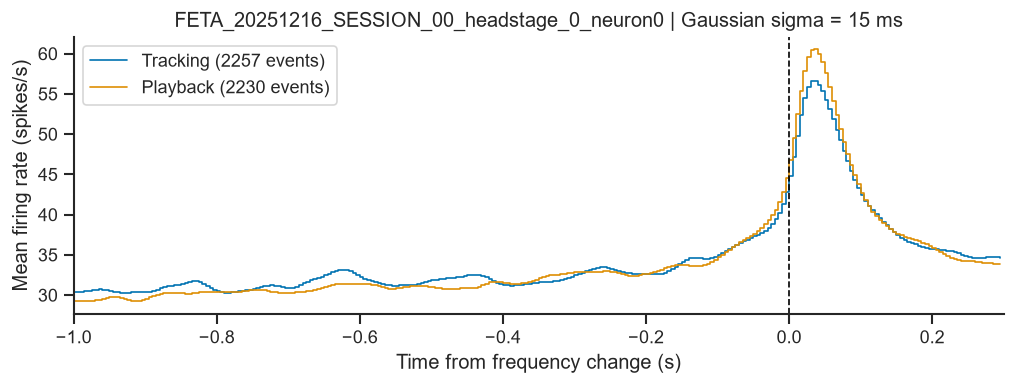

In [50]:
# Compare mean Gaussian-smoothed responses, converting counts/bin to spikes/s
import matplotlib.pyplot as plt

# None indicates a condition with no retained events.
tracking_mean_hz = tracking_responses.mean(axis=0) / dt if len(tracking_responses) else None
playback_mean_hz = playback_responses.mean(axis=0) / dt if len(playback_responses) else None

fig, ax = plt.subplots(figsize=(10, 3))
for label, responses, mean_hz in [
    ("Tracking", tracking_responses, tracking_mean_hz),
    ("Playback", playback_responses, playback_mean_hz),
]:
    if mean_hz is None:
        print(f"{label}: no events with a complete window.")
        continue
    ax.step(event_time_s, mean_hz, where="post", linewidth=1,
            label=f"{label} ({len(responses)} events)")

ax.axvline(0, color="black", linestyle="--", linewidth=1)
ax.set(
    xlabel="Time from frequency change (s)",
    ylabel="Mean firing rate (spikes/s)",
    title=f"{neuron_ids[session][unit]} | Gaussian sigma = {sigma_bins * dt * 1000:g} ms",
    xlim=(-before_bins * dt, after_bins * dt),
)
if tracking_mean_hz is not None or playback_mean_hz is not None:
    ax.legend()
plt.show()


## Responses grouped by the new played frequency

Run the event-extraction cells above first. This section reuses their selected neuron, time window, and Gaussian smoothing. Each event is grouped by `Played_frequency` **at its event bin** (the new played frequency). Each panel compares tracking and playback at one destination frequency, with shared axes and event counts in the legends. Other conditions and missing/nonfinite frequencies are excluded from this comparison.

`responses_by_frequency[frequency]["tracking"]` and `["playback"]` retain the event-by-time matrices in smoothed counts/bin. The plots show their means in spikes/s. Groups can have different numbers of events; a small group will give a less stable average. These are averages across transitions arriving at a frequency, not isolated-tone responses: preceding frequencies and nearby changes can also differ.


In [51]:
# Label every extracted event with its new played frequency
import numpy as np
import pandas as pd

event_frequencies = features[session]["Played_frequency"].iloc[event_bins].to_numpy(dtype=float)
frequency_valid = np.isfinite(event_frequencies)
comparison_mask = frequency_valid & (tracking_mask | playback_mask)
new_frequencies = np.unique(event_frequencies[comparison_mask])

# Keep a separate event-response matrix for each frequency and condition
responses_by_frequency = {}
frequency_counts = []
for frequency in new_frequencies:
    frequency_mask = frequency_valid & (event_frequencies == frequency)
    responses_by_frequency[frequency] = {
        "tracking": event_responses[frequency_mask & tracking_mask],
        "playback": event_responses[frequency_mask & playback_mask],
    }
    frequency_counts.append({
        "New played frequency (Hz)": frequency,
        "Tracking events": len(responses_by_frequency[frequency]["tracking"]),
        "Playback events": len(responses_by_frequency[frequency]["playback"]),
    })

print("Destination frequencies:", len(new_frequencies))
print("Tracking/playback events with missing or nonfinite frequency:",
      np.count_nonzero((tracking_mask | playback_mask) & ~frequency_valid))
display(pd.DataFrame(frequency_counts, columns=[
    "New played frequency (Hz)", "Tracking events", "Playback events",
]))


Destination frequencies: 15
Tracking/playback events with missing or nonfinite frequency: 0


,New played frequency (Hz),Tracking events,Playback events
0,533.0,2,2
1,617.0,21,21
2,715.0,46,46
3,828.0,98,98
4,959.0,171,171
5,1111.0,208,207
6,1287.0,210,208
7,1490.0,237,232
8,1727.0,241,234
9,2000.0,209,202


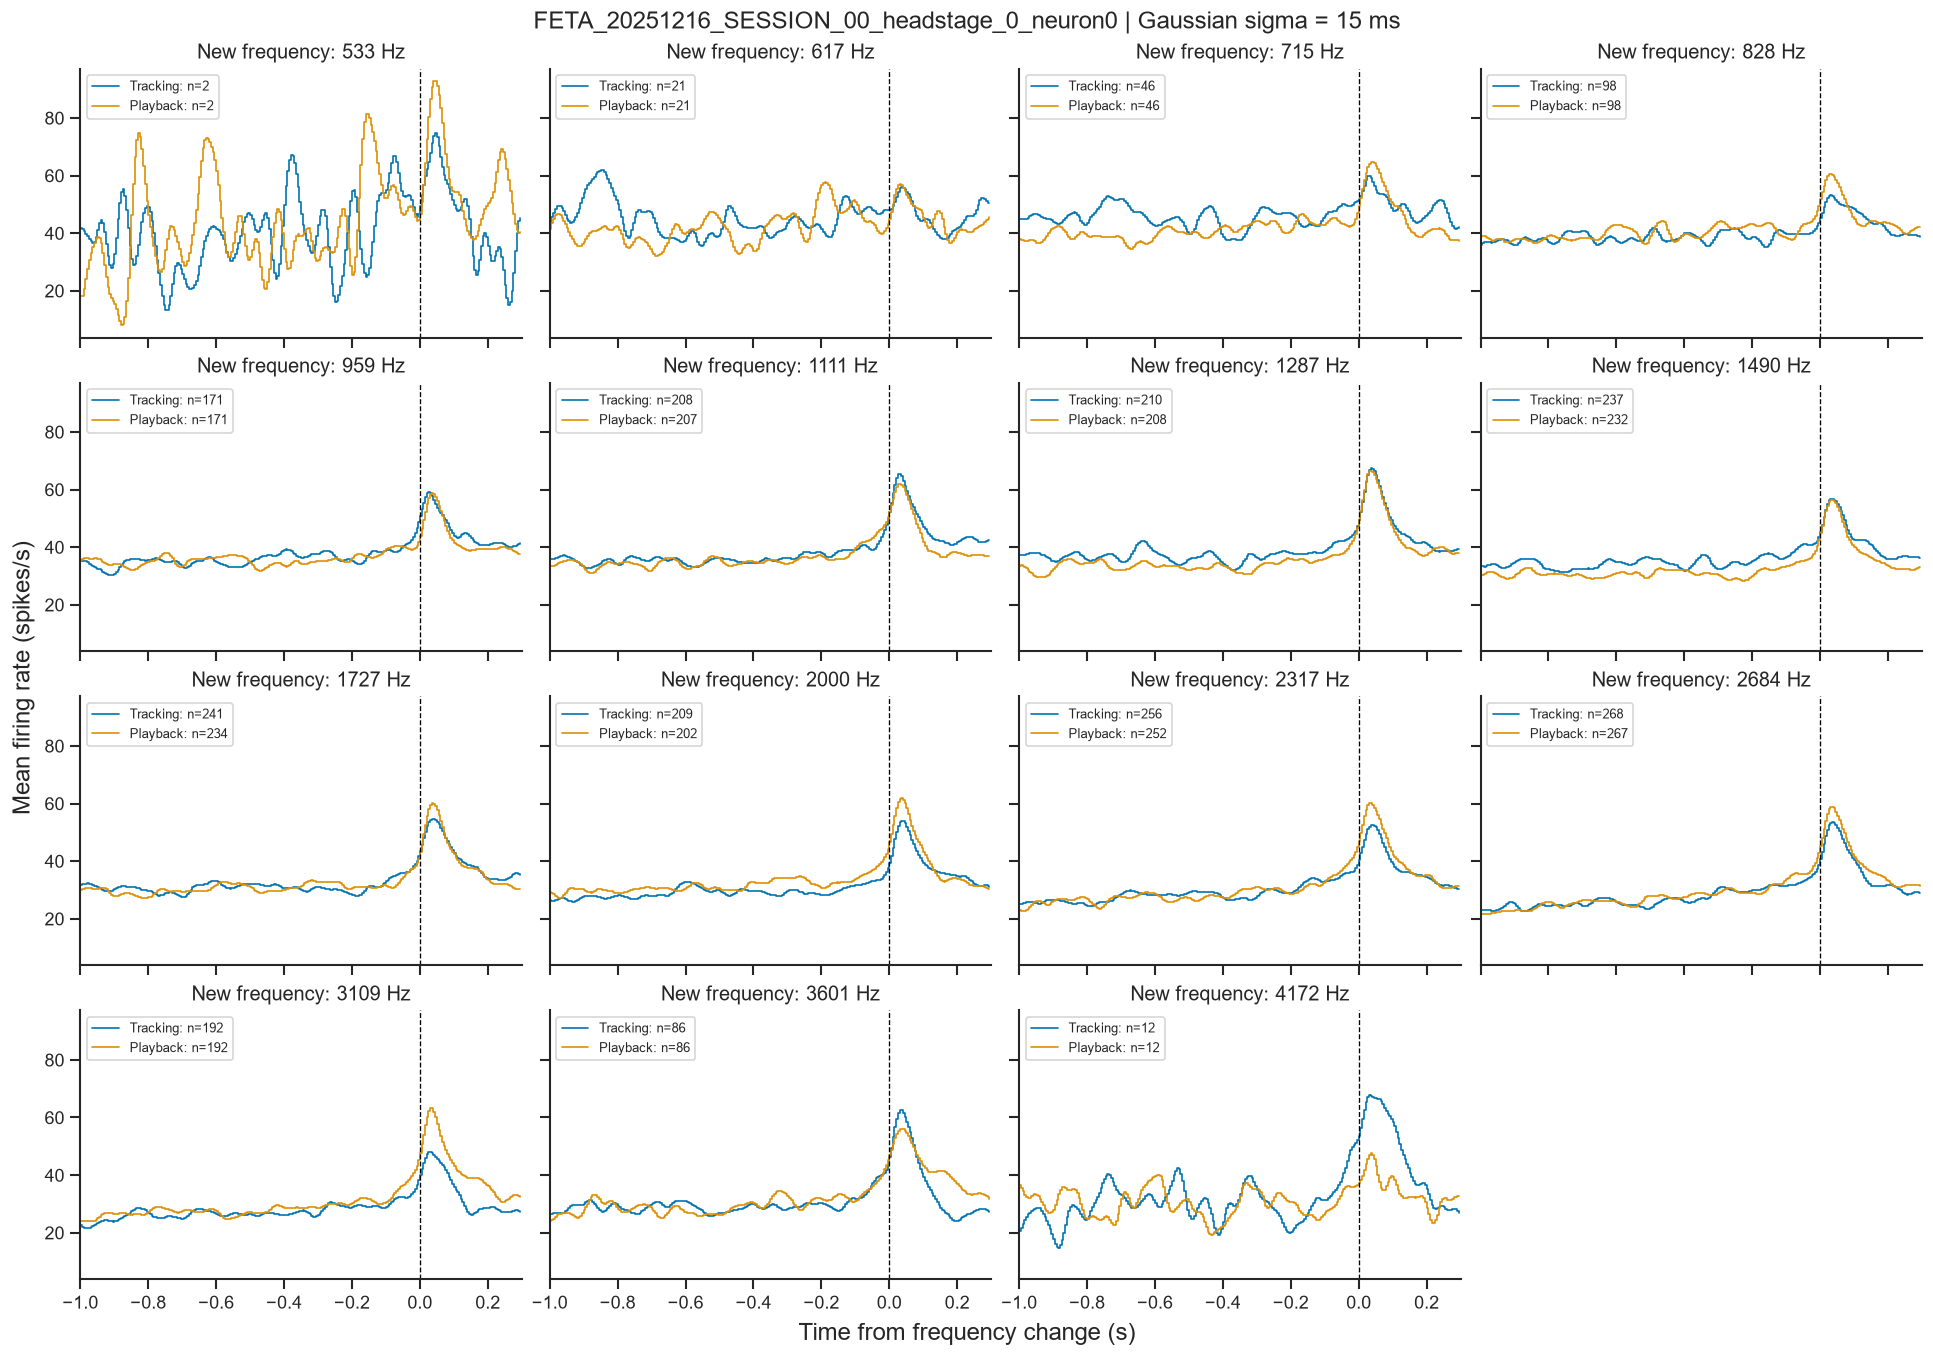

In [52]:
# Plot all destination frequencies, keeping the same scales for comparison
import matplotlib.pyplot as plt

if len(new_frequencies) == 0:
    raise ValueError("No tracking/playback events with a valid played frequency.")

ncols = min(4, len(new_frequencies))
nrows = int(np.ceil(len(new_frequencies) / ncols))
fig, axes = plt.subplots(
    nrows, ncols, figsize=(4 * ncols, 2.8 * nrows),
    sharex=True, sharey=True, squeeze=False, layout="constrained",
)

for ax, frequency in zip(axes.flat, new_frequencies):
    for condition, label, color in [
        ("tracking", "Tracking", "C0"),
        ("playback", "Playback", "C1"),
    ]:
        responses = responses_by_frequency[frequency][condition]
        if len(responses) == 0:
            continue
        ax.step(
            event_time_s, responses.mean(axis=0) / dt,
            where="post", linewidth=1, color=color,
            label=f"{label}: n={len(responses)}",
        )
    ax.axvline(0, color="black", linestyle="--", linewidth=0.8)
    ax.set_title(f"New frequency: {frequency:g} Hz")
    ax.set_xlim(-before_bins * dt, after_bins * dt)
    ax.legend(fontsize=8)

for ax in list(axes.flat)[len(new_frequencies):]:
    ax.set_visible(False)

fig.supxlabel("Time from frequency change (s)")
fig.supylabel("Mean firing rate (spikes/s)")
fig.suptitle(
    f"{neuron_ids[session][unit]} | Gaussian sigma = {sigma_bins * dt * 1000:g} ms"
)
plt.show()
